# Analizador de inversiones

Descarga precios historicos de Yahoo Finance, calcula metricas de riesgo y retorno y deja todo en un Excel que usa el dashboard de Power BI (`dashboards/analizador_inversiones.pbix`).

In [1]:
import os
from pathlib import Path

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tickers = ["AAPL", "SPY", "MSFT", "KO"]
benchmark = "SPY"
fecha_inicio = "2020-01-01"
fecha_fin = "2023-12-31"

# funciona tanto si se corre desde notebooks/ como desde la raiz
raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ruta_carpeta = raiz / "data" / "processed"
os.makedirs(ruta_carpeta, exist_ok=True)
ruta_archivo = ruta_carpeta / "datos_historicos_bolsa.xlsx"

## Descarga y limpieza

In [2]:
df_precios = yf.download(tickers, start=fecha_inicio, end=fecha_fin, auto_adjust=True, progress=False)["Close"]
df_precios = df_precios.ffill()

# ^IRX es la tasa de los T-bills a 13 semanas, viene en porcentaje
irx = yf.download("^IRX", start=fecha_inicio, end=fecha_fin, auto_adjust=True, progress=False)["Close"]
tasa_libre_riesgo = irx.squeeze().mean() / 100

print(f"Dias de datos: {len(df_precios)}")
print(f"Tasa libre de riesgo promedio: {tasa_libre_riesgo:.2%}")
df_precios.tail()

Dias de datos: 1006
Tasa libre de riesgo promedio: 1.84%


Ticker,AAPL,KO,MSFT,SPY
Date,,,,
2023-12-22,191.268158,53.922443,366.750397,458.641022
2023-12-26,190.724747,54.144352,366.828705,460.577606
2023-12-27,190.823563,54.283035,366.251068,461.410370
2023-12-28,191.248367,54.320011,367.435699,461.584717
2023-12-29,190.211029,54.486443,368.179871,460.248444


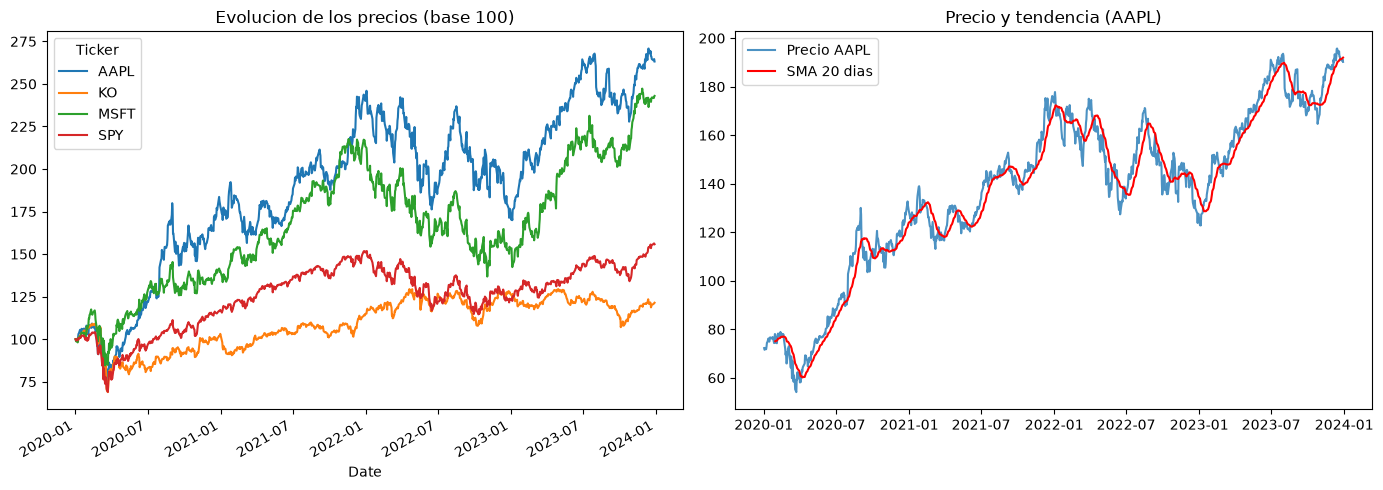

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# base 100 para poder comparar activos con precios muy distintos
(df_precios / df_precios.iloc[0] * 100).plot(ax=axes[0])
axes[0].set_title("Evolucion de los precios (base 100)")

sma_20 = df_precios["AAPL"].rolling(window=20).mean()
axes[1].plot(df_precios.index, df_precios["AAPL"], label="Precio AAPL", alpha=0.8)
axes[1].plot(df_precios.index, sma_20, label="SMA 20 dias", color="red")
axes[1].set_title("Precio y tendencia (AAPL)")
axes[1].legend()

plt.tight_layout()
plt.show()

## Metricas de riesgo y retorno

- **Retorno_Anual**: retorno diario promedio x 252.
- **CAGR**: crecimiento anual compuesto real del periodo.
- **Volatilidad_Anual**: desviacion estandar diaria x raiz de 252.
- **Ratio_Sharpe**: (retorno anual - tasa libre de riesgo) / volatilidad.
- **Max_Drawdown**: peor caida desde un maximo.
- **Beta**: sensibilidad frente al benchmark (SPY).

In [4]:
returns = df_precios.pct_change(fill_method=None).dropna()

retorno_anual = returns.mean() * 252
volatilidad_anual = returns.std() * np.sqrt(252)
ratio_sharpe = (retorno_anual - tasa_libre_riesgo) / volatilidad_anual

anios = (df_precios.index[-1] - df_precios.index[0]).days / 365.25
cagr = (df_precios.iloc[-1] / df_precios.iloc[0]) ** (1 / anios) - 1

max_drawdown = (df_precios / df_precios.cummax() - 1).min()
beta = returns.cov()[benchmark] / returns[benchmark].var()

# las tres primeras columnas las usa el dashboard, no cambiarles el nombre
df_resumen = pd.DataFrame({
    "Retorno_Anual": retorno_anual,
    "Volatilidad_Anual": volatilidad_anual,
    "Ratio_Sharpe": ratio_sharpe,
    "CAGR": cagr,
    "Max_Drawdown": max_drawdown,
    "Beta": beta,
}).sort_values("Ratio_Sharpe", ascending=False)

df_resumen.round(3)

,Retorno_Anual,Volatilidad_Anual,Ratio_Sharpe,CAGR,Max_Drawdown,Beta
Ticker,,,,,,
AAPL,0.299,0.336,0.836,0.275,-0.314,1.210
MSFT,0.276,0.326,0.789,0.249,-0.371,1.190
SPY,0.137,0.226,0.524,0.118,-0.337,1.000
KO,0.074,0.224,0.248,0.050,-0.370,0.674


In [5]:
correlaciones = returns.corr()
correlaciones.round(2)

Ticker,AAPL,KO,MSFT,SPY
Ticker,,,,
AAPL,1.00,0.47,0.78,0.82
KO,0.47,1.00,0.47,0.68
MSFT,0.78,0.47,1.00,0.83
SPY,0.82,0.68,0.83,1.00


## Exportar a Excel

In [6]:
with pd.ExcelWriter(ruta_archivo, engine="openpyxl") as writer:
    df_precios.to_excel(writer, sheet_name="Precios_Historicos", index=True)
    df_resumen.to_excel(writer, sheet_name="Resumen_Sharpe", index=True)
    correlaciones.to_excel(writer, sheet_name="Correlaciones", index=True)

print(f"Guardado en {ruta_archivo.relative_to(raiz)}")

Guardado en data\processed\datos_historicos_bolsa.xlsx
